# Aviation Accidents Analysis

You are part of a consulting firm that is tasked to do an analysis of commercial and passenger jet airline safety. The client (an airline/airplane insurer) is interested in knowing what types of aircraft (makes/models) exhibit low rates of total destruction and low likelihood of fatal or serious passenger injuries in the event of an accident. They are also interested in any general variables/conditions that might be at play. Your analysis will be based off of aviation accident data accumulated from the years 1948-2023. 

Our client is only interested in airplane makes/models that are professional builds and could potentially still be active. Assume a max lifetime of 40 years for a make/model retirement and make sure to filter your data accordingly (i.e. from 1983 onwards). They would also like separate recommendations for small aircraft vs. larger passenger models. **In addition, make sure that claims that you make are statistically robust and that you have enough samples when making comparisons between groups.**


In this summative assessment you will demonstrate your ability to:
- Use Pandas to load, inspect, and clean the dataset appropriately. 
- Transform relevant columns to create measures that address the problem at hand.
- **conduct EDA: visualization and statistical measures to understand the structure of the data**
- **recommend a set of manufacturers to consider as well as specific airplanes conforming to the client's request**
- **discuss the relationship between serious injuries/airplane damage incurred and at least *two* factors at play in the incident. You must provide supporting evidence (visuals, summary statistics, tables) for each claim you make.**

In [20]:
# loading relevant packages
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Exploratory Data Analysis  
- Load in the cleaned data

In [21]:
# Load the cleaned aviation dataset
aviation_df = pd.read_csv("cleaned_aviation_data.csv")

# Display the first 5 rows
display(aviation_df.head())

# Check the number of rows and columns
print("Dataset shape:", aviation_df.shape)

# Check column names and data types
aviation_df.info()

,Event.Id,Investigation.Type,Accident.Number,Event.Date,Location,Country,Latitude,Longitude,Airport.Code,Airport.Name,...,FAR.Description,Purpose.of.flight,Total.Fatal.Injuries,Total.Serious.Injuries,Total.Minor.Injuries,Total.Uninjured,Weather.Condition,Report.Status,Publication.Date,Aircraft.Destroyed
0,20001214X42478,Incident,LAX83IA149A,1983-03-18,"LOS ANGELES, CA",United States,NaN,NaN,LAX,LOS ANGELES INTL,...,Part 129: Foreign,NaN,NaN,NaN,NaN,588.0,Vmc,Probable Cause,04-12-2014,0.0
1,20001214X42331,Accident,ATL83FA140,1983-03-20,"CROSSVILLE, TN",United States,NaN,NaN,NaN,NaN,...,Part 91: General Aviation,Personal,1.0,1.0,NaN,NaN,Imc,Probable Cause,02-05-2011,1.0
2,20001214X42672,Accident,FTW83LA177,1983-04-02,"MCKINNEY, TX",United States,NaN,NaN,TX05,AERO COUNTRY,...,Part 91: General Aviation,Skydiving,1.0,NaN,NaN,4.0,Vmc,Probable Cause,17-10-2016,NaN
3,20001214X44248,Incident,MIA83IA210,1983-08-21,"NORFOLK, VA",United States,NaN,NaN,NaN,NaN,...,Part 121: Air Carrier,Unknown,NaN,NaN,NaN,289.0,Vmc,Probable Cause,01-02-2016,0.0
4,20001214X45013,Incident,CHI84IA041,1983-11-08,"CHICAGO, IL",United States,NaN,NaN,ORD,O'HARE,...,Part 121: Air Carrier,Unknown,NaN,NaN,NaN,100.0,Vmc,Probable Cause,11-06-2018,0.0


Dataset shape: (18278, 29)
<class 'pandas.DataFrame'>
RangeIndex: 18278 entries, 0 to 18277
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Event.Id                18278 non-null  str    
 1   Investigation.Type      18278 non-null  str    
 2   Accident.Number         18278 non-null  str    
 3   Event.Date              18278 non-null  str    
 4   Location                18273 non-null  str    
 5   Country                 18277 non-null  str    
 6   Latitude                16332 non-null  str    
 7   Longitude               16329 non-null  str    
 8   Airport.Code            11906 non-null  str    
 9   Airport.Name            12010 non-null  str    
 10  Injury.Severity         17556 non-null  str    
 11  Aircraft.damage         17184 non-null  str    
 12  Aircraft.Category       18278 non-null  str    
 13  Registration.Number     18105 non-null  str    
 14  Make                  

## Explore safety metrics across models/makes
- Remember that the client is interested in separate recommendations for smaller airplanes and larger airplanes. Choose a passenger threshold of 20 and separate the plane types. 

In [22]:
# Convert injury columns to numeric values
injury_columns = [
    "Total.Fatal.Injuries",
    "Total.Serious.Injuries",
    "Total.Minor.Injuries",
    "Total.Uninjured"
]

for col in injury_columns:
    aviation_df[col] = pd.to_numeric(
        aviation_df[col], errors="coerce"
    )

# Estimate total occupants only when all four counts are available
aviation_df["Estimated.Total.Occupants"] = (
    aviation_df[injury_columns].sum(axis=1, min_count=4)
)

# Check the new column
display(aviation_df[["Estimated.Total.Occupants"]].head())

,Estimated.Total.Occupants
0,NaN
1,NaN
2,NaN
3,NaN
4,NaN


In [23]:
# Set the threshold
passenger_threshold = 20

# Separate smaller and larger aircraft
smaller_airplanes = aviation_df[
    aviation_df["Estimated.Total.Occupants"] < passenger_threshold
].copy()

larger_airplanes = aviation_df[
    aviation_df["Estimated.Total.Occupants"] >= passenger_threshold
].copy()

# Display the results
print("Smaller aircraft:", smaller_airplanes.shape)
print("Larger aircraft:", larger_airplanes.shape)

Smaller aircraft: (14793, 30)
Larger aircraft: (813, 30)


#### Analyzing Makes

Explore the human injury risk profile for small and larger Makes:
- choose the 15 makes for each group possessing the lowest mean fatal/seriously injured fraction
- plot the mean fatal/seriously injured fraction for each of these subgroups side-by-side

In [24]:
# Calculate fatal + serious injuries
aviation_df["Fatal_Serious_Injuries"] = (
    aviation_df["Total.Fatal.Injuries"].fillna(0)
    + aviation_df["Total.Serious.Injuries"].fillna(0)
)

# Calculate injury fraction among estimated occupants
aviation_df["Serious.Fatal.Injury.Fraction"] = (
    aviation_df["Fatal_Serious_Injuries"]
    / aviation_df["Estimated.Total.Occupants"].replace(0, np.nan)
)

# Check the result
aviation_df[
    ["Make", "Estimated.Total.Occupants",
     "Fatal_Serious_Injuries", "Serious.Fatal.Injury.Fraction"]
].head()


,Make,Estimated.Total.Occupants,Fatal_Serious_Injuries,Serious.Fatal.Injury.Fraction
0,BOEING,NaN,0.0,NaN
1,PIPER,NaN,2.0,NaN
2,DE HAVILLAND,NaN,1.0,NaN
3,DOUGLAS,NaN,0.0,NaN
4,BOEING,NaN,0.0,NaN


In [25]:

# Separate small and larger aircraft
small_aircraft = aviation_df[
    aviation_df["Estimated.Total.Occupants"] < 20
].copy()

large_aircraft = aviation_df[
    aviation_df["Estimated.Total.Occupants"] >= 20
].copy()

# Function to calculate the 15 lowest mean injury fractions
def get_lowest_15(data):
    return (
        data.dropna(subset=["Make", "Serious.Fatal.Injury.Fraction"])
        .groupby("Make")
        .agg(
            mean_injury_fraction=("Serious.Fatal.Injury.Fraction", "mean"),
            accident_count=("Serious.Fatal.Injury.Fraction", "count")
        )
        .query("accident_count >= 50")
        .nsmallest(15, "mean_injury_fraction")
        .reset_index()
    )

small_means = get_lowest_15(small_aircraft)
large_means = get_lowest_15(large_aircraft)

display(small_means)
display(large_means)


,Make,mean_injury_fraction,accident_count
0,BOEING,0.156968,232
1,AVIAT AIRCRAFT INC,0.164474,76
2,MAULE,0.192593,171
3,GRUMMAN ACFT ENG COR-SCHWEIZER,0.206897,58
4,DIAMOND AIRCRAFT IND INC,0.222973,74
5,DEHAVILLAND,0.234170,92
6,ROCKWELL INTERNATIONAL,0.236111,54
7,AERONCA,0.245040,168
8,STINSON,0.249256,112
9,BELLANCA,0.252825,177


,Make,mean_injury_fraction,accident_count
0,BOEING,0.051341,486
1,EMBRAER,0.056642,73
2,AIRBUS,0.080503,114


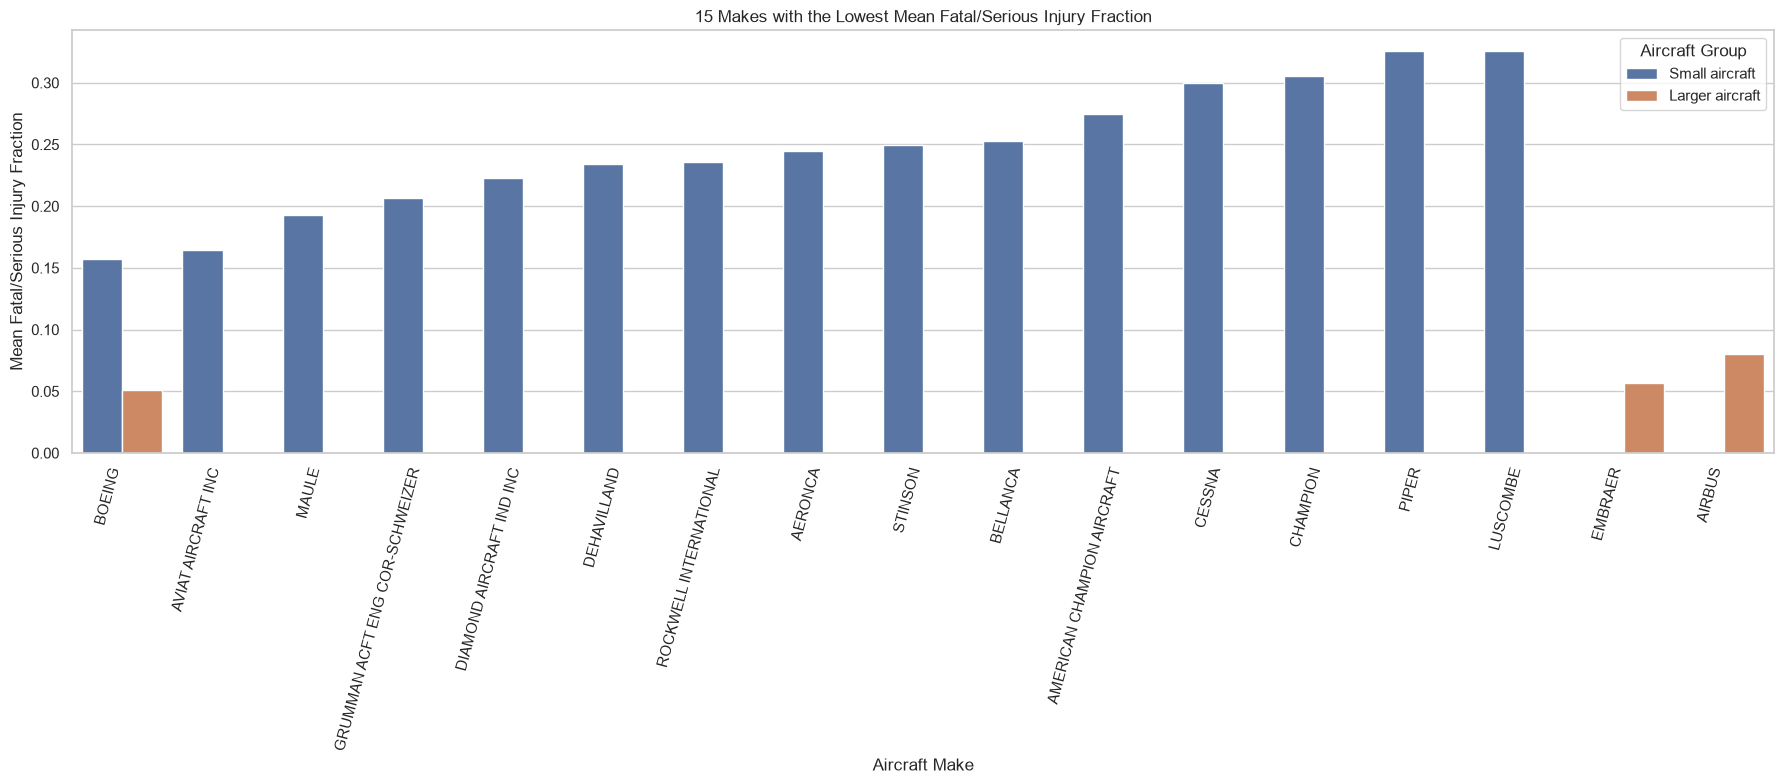

In [26]:

plot_df = pd.concat([
    small_means.assign(Aircraft_Group="Small aircraft"),
    large_means.assign(Aircraft_Group="Larger aircraft")
], ignore_index=True)

plt.figure(figsize=(18, 8))

sns.barplot(
    data=plot_df,
    x="Make",
    y="mean_injury_fraction",
    hue="Aircraft_Group",
    dodge=True
)

plt.title("15 Makes with the Lowest Mean Fatal/Serious Injury Fraction")
plt.xlabel("Aircraft Make")
plt.ylabel("Mean Fatal/Serious Injury Fraction")
plt.xticks(rotation=75, ha="right")
plt.legend(title="Aircraft Group")
plt.tight_layout()
plt.show()


**Distribution of injury rates: small makes**

Use a violinplot to look at the distribution of the fraction of passengers serious/fatally injured for small airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

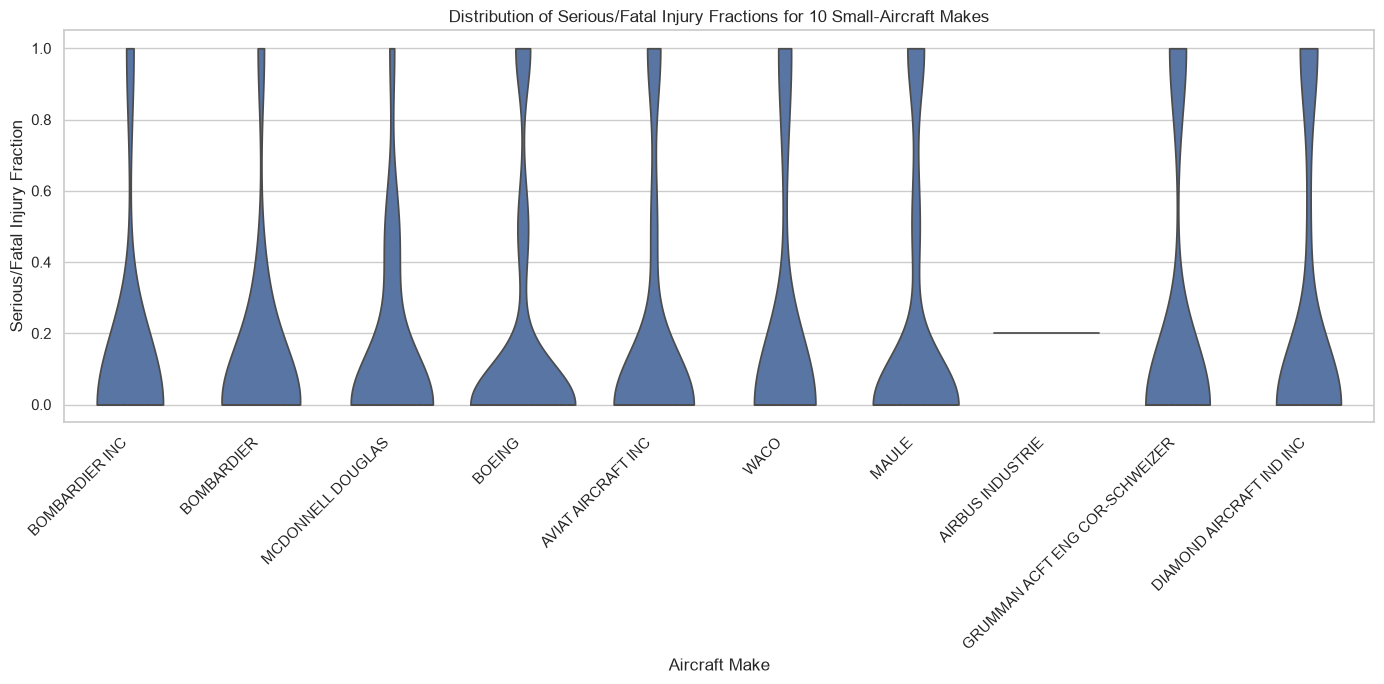

In [27]:


# Filter small aircraft (fewer than 20 occupants)
small_aircraft = aviation_df[
    aviation_df["Estimated.Total.Occupants"] < 20
].copy()

# Remove missing values needed for the analysis
small_aircraft = small_aircraft.dropna(
    subset=["Make", "Serious.Fatal.Injury.Fraction"]
)

# Select the 10 makes with the lowest mean injury fraction
lowest_10_makes = (
    small_aircraft.groupby("Make")["Serious.Fatal.Injury.Fraction"]
    .mean()
    .nsmallest(10)
    .index
)

# Keep only those 10 makes
plot_data = small_aircraft[
    small_aircraft["Make"].isin(lowest_10_makes)
]

# Create violin plot
plt.figure(figsize=(14, 7))

sns.violinplot(
    data=plot_data,
    x="Make",
    y="Serious.Fatal.Injury.Fraction",
    order=lowest_10_makes,
    inner="quartile",
    cut=0
)

plt.title("Distribution of Serious/Fatal Injury Fractions for 10 Small-Aircraft Makes")
plt.xlabel("Aircraft Make")
plt.ylabel("Serious/Fatal Injury Fraction")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Distribution of injury rates: large makes**

Use a stripplot to look at the distribution of the fraction of passengers serious/fatally injured for large airplane makes. Just display makes with the ten lowest mean serious/fatal injury rates.

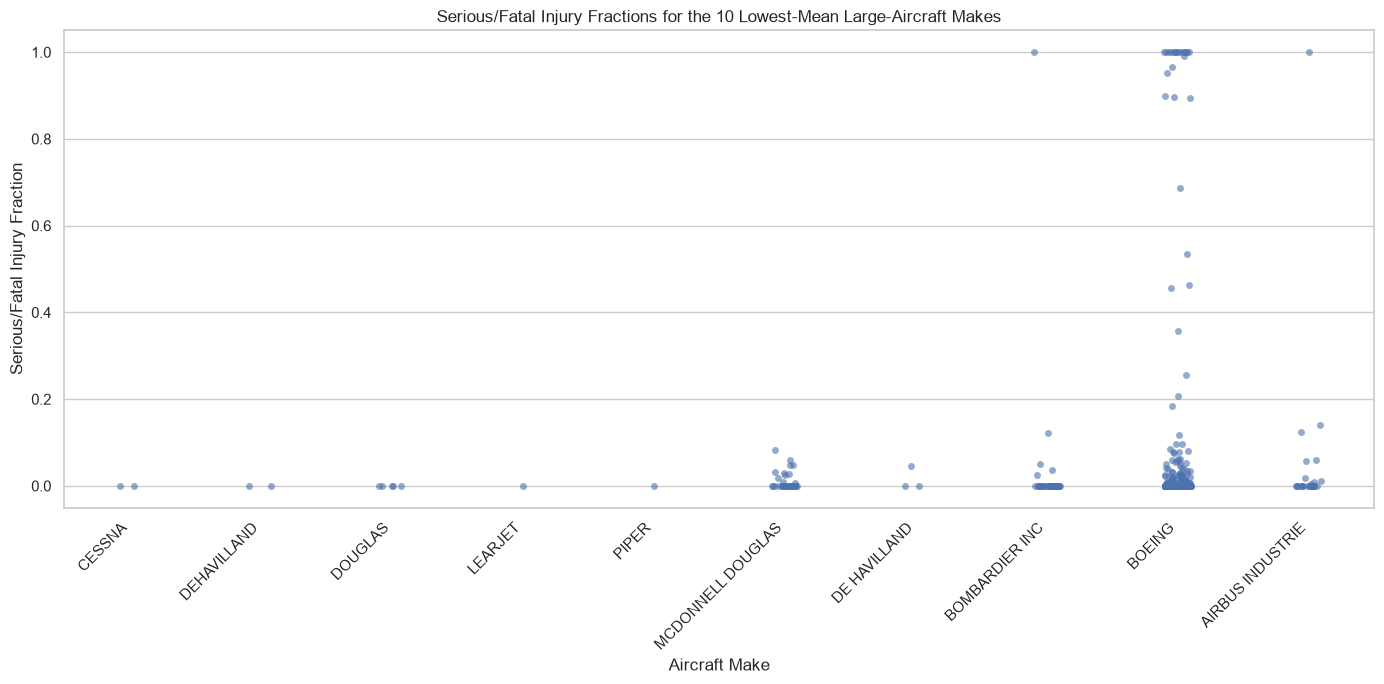

In [28]:

# Filter large aircraft (20 or more occupants)
large_aircraft = aviation_df[
    aviation_df["Estimated.Total.Occupants"] >= 20
].copy()

# Remove missing values
large_aircraft = large_aircraft.dropna(
    subset=["Make", "Serious.Fatal.Injury.Fraction"]
)

# Find the 10 makes with the lowest mean injury fraction
lowest_10_makes = (
    large_aircraft.groupby("Make")["Serious.Fatal.Injury.Fraction"]
    .mean()
    .nsmallest(10)
    .index
)

# Select only those makes
plot_data = large_aircraft[
    large_aircraft["Make"].isin(lowest_10_makes)
]

# Create stripplot
plt.figure(figsize=(14, 7))

sns.stripplot(
    data=plot_data,
    x="Make",
    y="Serious.Fatal.Injury.Fraction",
    order=lowest_10_makes,
    jitter=True,
    alpha=0.6
)

plt.title(
    "Serious/Fatal Injury Fractions for the 10 Lowest-Mean Large-Aircraft Makes"
)
plt.xlabel("Aircraft Make")
plt.ylabel("Serious/Fatal Injury Fraction")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


**Evaluate the rate of aircraft destruction for both small and large aircraft by Make.** 

Sort your results and keep the lowest 15.

In [29]:
# Calculate mean injury fraction for large aircraft makes
lowest_15_makes = (
    large_aircraft.groupby("Make")["Serious.Fatal.Injury.Fraction"]
    .mean()
    .sort_values(ascending=True)
    .head(15)
)

# Display results
lowest_15_makes

Make
CESSNA                       0.000000
LEARJET                      0.000000
DOUGLAS                      0.000000
DEHAVILLAND                  0.000000
PIPER                        0.000000
MCDONNELL DOUGLAS            0.011661
DE HAVILLAND                 0.015152
BOMBARDIER INC               0.028038
BOEING                       0.051341
AIRBUS INDUSTRIE             0.052599
EMBRAER                      0.056642
BOMBARDIER                   0.070406
AIRBUS                       0.080503
RAYTHEON AIRCRAFT COMPANY    0.150000
BEECH                        1.000000
Name: Serious.Fatal.Injury.Fraction, dtype: float64

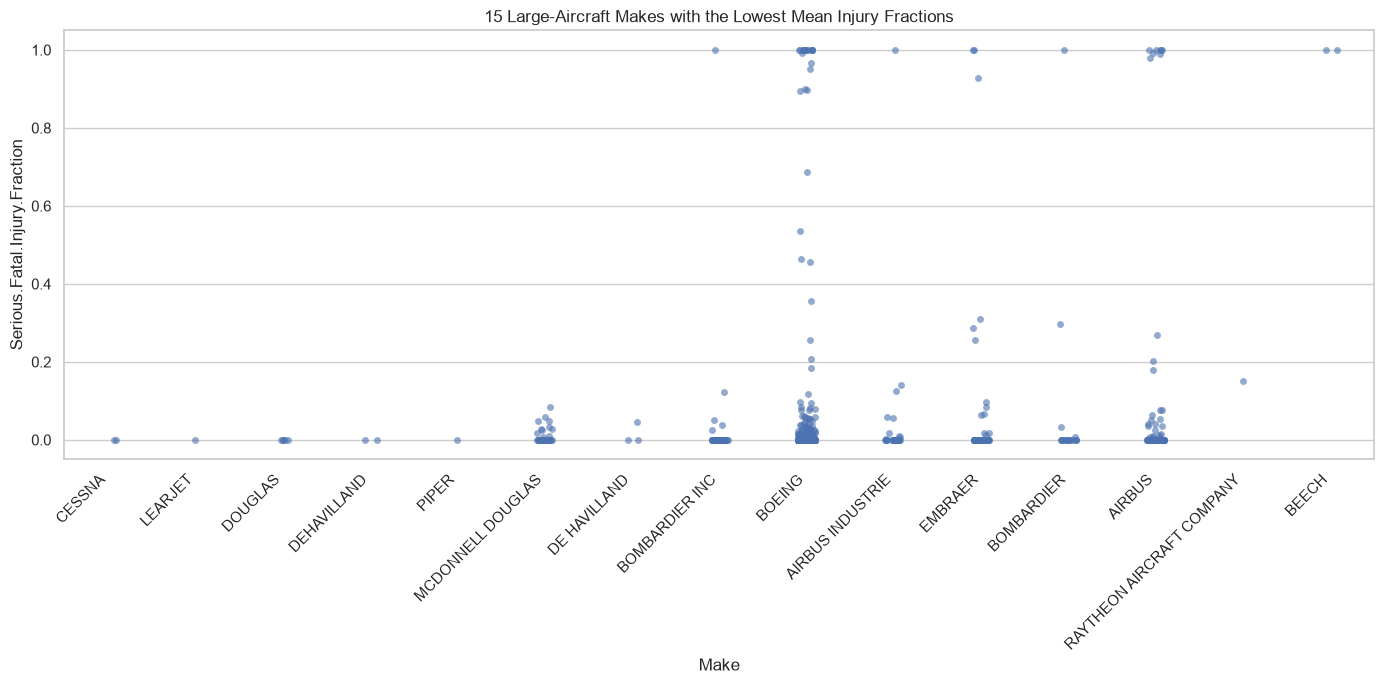

In [30]:
# Select the 15 makes
selected_makes = lowest_15_makes.index

plot_data = large_aircraft[
    large_aircraft["Make"].isin(selected_makes)
]

plt.figure(figsize=(14, 7))

sns.stripplot(
    data=plot_data,
    x="Make",
    y="Serious.Fatal.Injury.Fraction",
    order=selected_makes,
    jitter=True,
    alpha=0.6
)

plt.xticks(rotation=45, ha="right")
plt.title("15 Large-Aircraft Makes with the Lowest Mean Injury Fractions")
plt.tight_layout()
plt.show()

#### Provide a short discussion on your findings for your summary statistics and plots:
- Make any recommendations for Makes here based off of the destroyed fraction and fraction fatally/seriously injured
- Comment on the calculated statistics and any corresponding distributions you have visualized.

### Analyze plane types
- plot the mean fatal/seriously injured fraction for both small and larger planes 
- also provide a distributional plot of your choice for the fatal/seriously injured fraction by airplane type (stripplot, violin, etc)  
- filter ensuring that you have at least ten individual examples in each model/make to average over

**Larger planes**

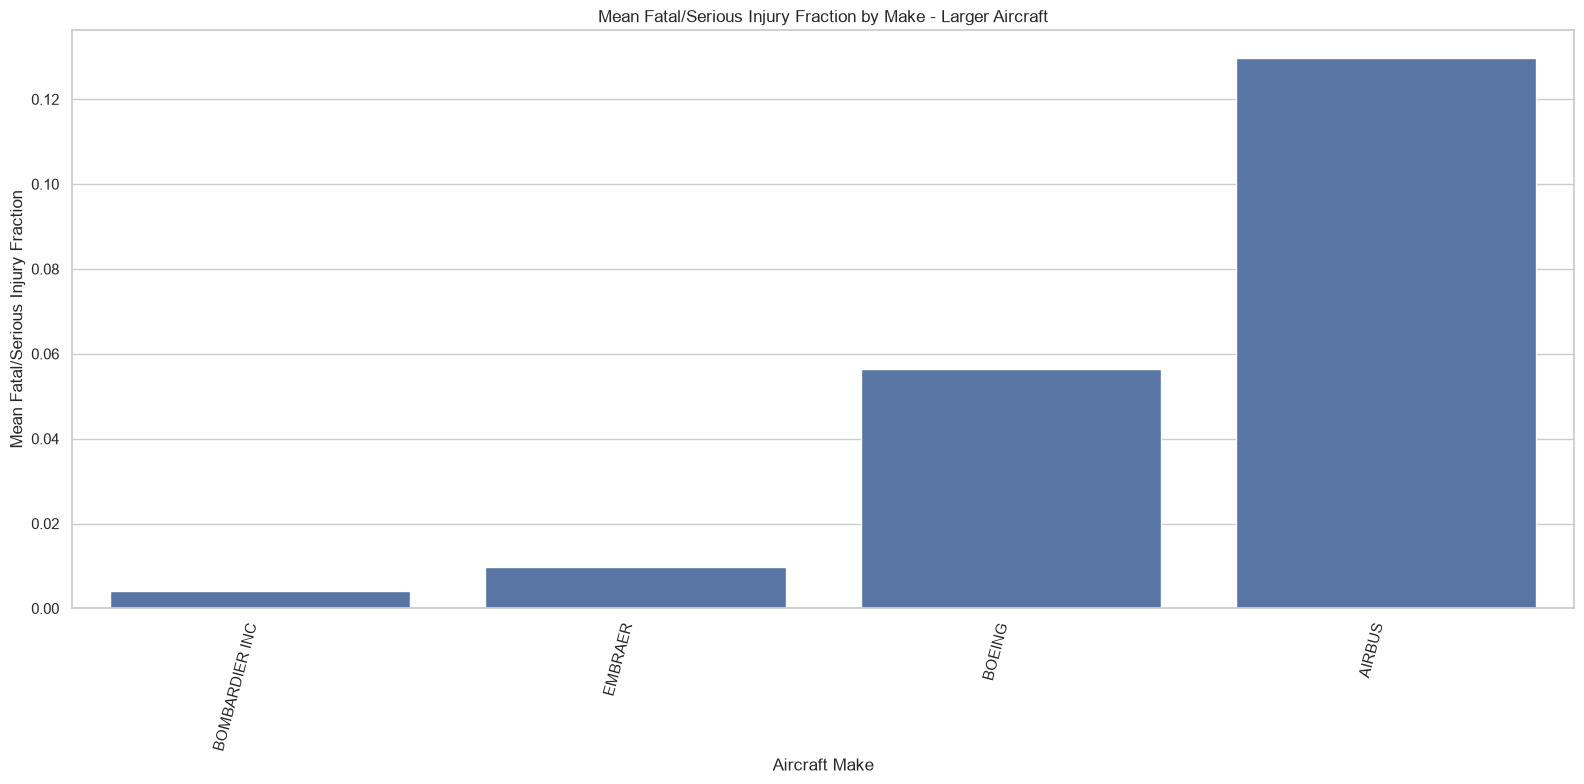

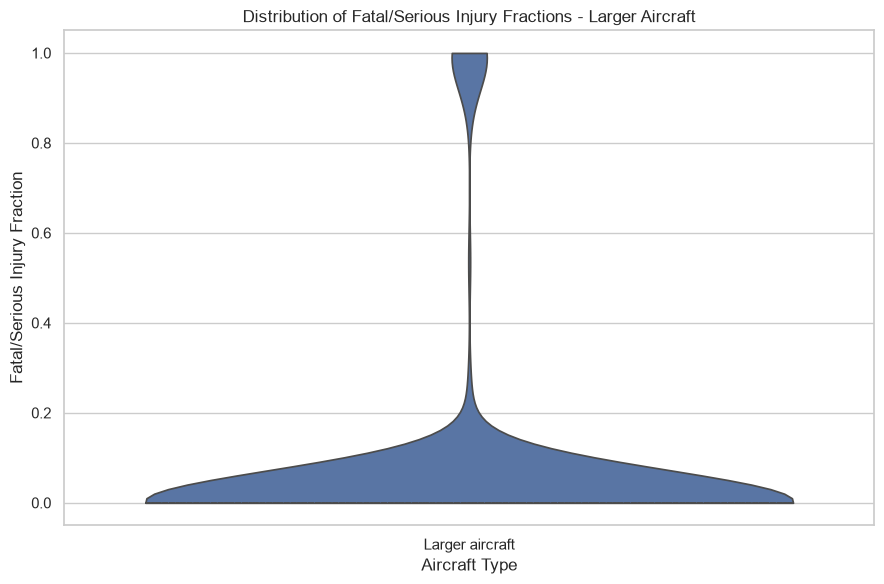

mean        0.060449
median      0.000000
count     371.000000
Name: Serious.Fatal.Injury.Fraction, dtype: float64

In [31]:
# 1. Filter larger aircraft (20 or more occupants)
large_planes = aviation_df[
    aviation_df["Estimated.Total.Occupants"] >= 20
].copy()

# 2. Remove missing values
large_planes = large_planes.dropna(
    subset=[
        "Make",
        "Model",
        "Serious.Fatal.Injury.Fraction"
    ]
)

# 3. Keep make/model combinations with at least 10 records
model_counts = large_planes.groupby(
    ["Make", "Model"]
).size().reset_index(name="Record_Count")

valid_models = model_counts[
    model_counts["Record_Count"] >= 10
][["Make", "Model"]]

large_planes = large_planes.merge(
    valid_models,
    on=["Make", "Model"],
    how="inner"
)

# 4. Calculate mean injury fraction by make
mean_by_make = (
    large_planes.groupby("Make")["Serious.Fatal.Injury.Fraction"]
    .mean()
    .sort_values()
    .reset_index(name="Mean_Injury_Fraction")
)

# 5. Plot mean injury fraction by make
plt.figure(figsize=(16, 8))

sns.barplot(
    data=mean_by_make,
    x="Make",
    y="Mean_Injury_Fraction",
    errorbar=None
)

plt.title("Mean Fatal/Serious Injury Fraction by Make - Larger Aircraft")
plt.xlabel("Aircraft Make")
plt.ylabel("Mean Fatal/Serious Injury Fraction")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.show()

# 6. Plot injury-fraction distribution
plt.figure(figsize=(9, 6))

sns.violinplot(
    data=large_planes,
    x=["Larger aircraft"] * len(large_planes),
    y="Serious.Fatal.Injury.Fraction",
    inner="quartile",
    cut=0
)

plt.title("Distribution of Fatal/Serious Injury Fractions - Larger Aircraft")
plt.xlabel("Aircraft Type")
plt.ylabel("Fatal/Serious Injury Fraction")
plt.tight_layout()
plt.show()

# 7. Display summary statistics
display(
    large_planes["Serious.Fatal.Injury.Fraction"]
    .agg(["mean", "median", "count"])
)


**Smaller planes**
- for smaller planes, limit your plotted results to the makes with the 10 lowest mean serious/fatal injury fractions

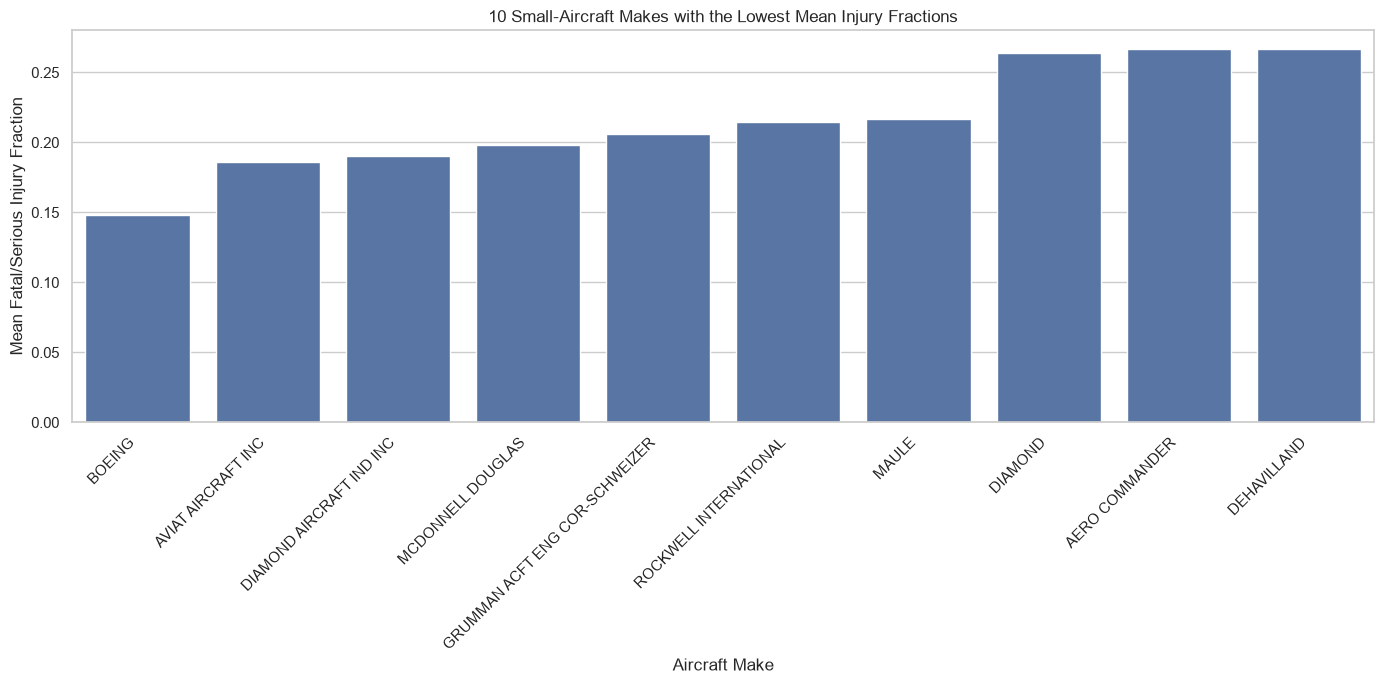

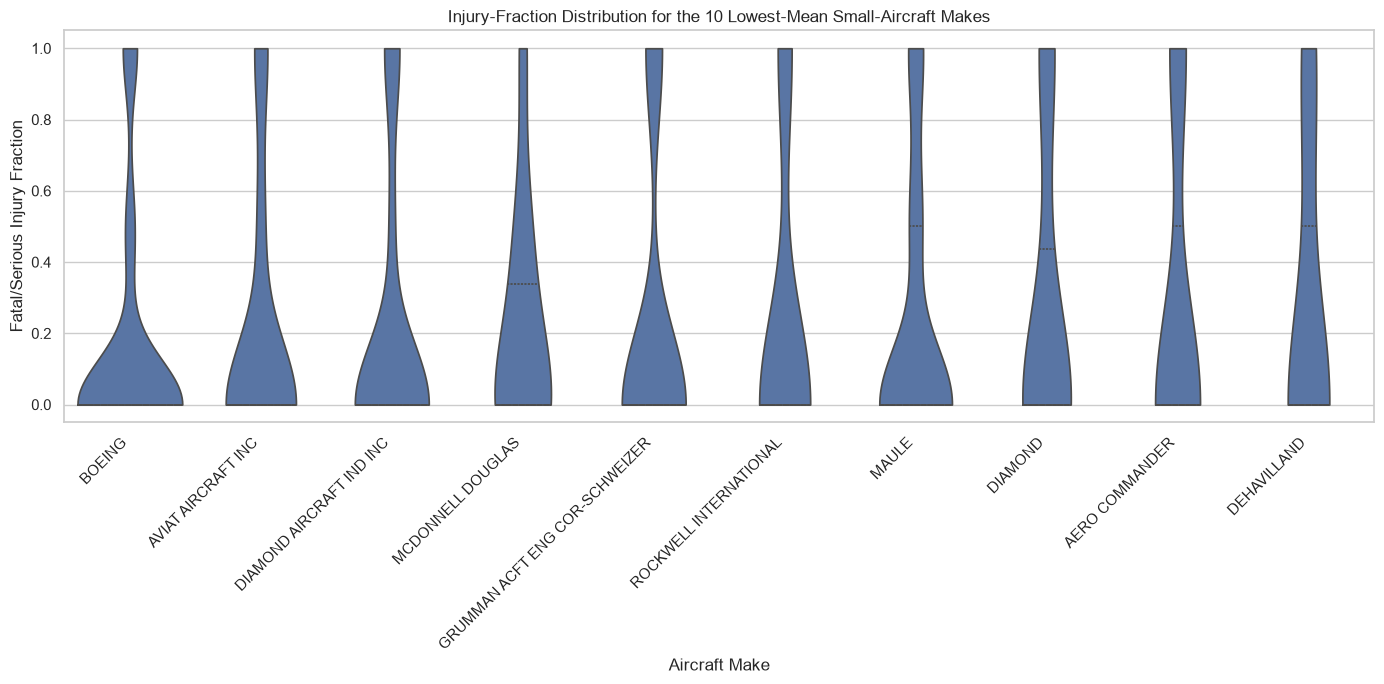

In [32]:
# 1. Filter small aircraft (fewer than 20 occupants)
small_planes = aviation_df[
    aviation_df["Estimated.Total.Occupants"] < 20
].copy()

# 2. Remove missing values
small_planes = small_planes.dropna(
    subset=[
        "Make",
        "Model",
        "Serious.Fatal.Injury.Fraction"
    ]
)

# 3. Keep make/model combinations with at least 10 records
model_counts = (
    small_planes.groupby(["Make", "Model"])
    .size()
    .reset_index(name="Record_Count")
)

valid_models = model_counts[
    model_counts["Record_Count"] >= 10
][["Make", "Model"]]

small_planes = small_planes.merge(
    valid_models,
    on=["Make", "Model"],
    how="inner"
)

# 4. Find the 10 makes with the lowest mean injury fractions
lowest_10_makes = (
    small_planes.groupby("Make")["Serious.Fatal.Injury.Fraction"]
    .mean()
    .sort_values()
    .head(10)
    .index
)

# Keep only those 10 makes
plot_data = small_planes[
    small_planes["Make"].isin(lowest_10_makes)
].copy()

# 5. Plot mean injury fraction by make
plt.figure(figsize=(14, 7))

sns.barplot(
    data=plot_data,
    x="Make",
    y="Serious.Fatal.Injury.Fraction",
    order=lowest_10_makes,
    errorbar=None
)

plt.title("10 Small-Aircraft Makes with the Lowest Mean Injury Fractions")
plt.xlabel("Aircraft Make")
plt.ylabel("Mean Fatal/Serious Injury Fraction")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# 6. Violin plot showing the distribution
plt.figure(figsize=(14, 7))

sns.violinplot(
    data=plot_data,
    x="Make",
    y="Serious.Fatal.Injury.Fraction",
    order=lowest_10_makes,
    inner="quartile",
    cut=0
)

plt.title("Injury-Fraction Distribution for the 10 Lowest-Mean Small-Aircraft Makes")
plt.xlabel("Aircraft Make")
plt.ylabel("Fatal/Serious Injury Fraction")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


### Discussion of Specific Airplane Types
- Discuss what you have found above regarding passenger fraction seriously/ both small and large airplane models.

### Exploring Other Variables
- Investigate how other variables effect aircraft damage and injury. You must choose **two** factors out of the following but are free to analyze more:

- Weather Condition
- Engine Type
- Number of Engines
- Phase of Flight
- Purpose of Flight

For each factor provide a discussion explaining your analysis with appropriate visualization / data summaries and interpreting your findings.

,Accident_Count,Severe_Damage_Rate,Mean_Fatal_Injuries,Mean_Serious_Injuries,Mean_Injury_Fraction
Weather.Condition,,,,,
VMC,14605,0.960356,0.316638,0.319254,0.263319
IMC,926,0.922246,2.468605,0.406675,0.638343
UNKNOWN,279,0.584229,2.183962,0.712871,0.486294


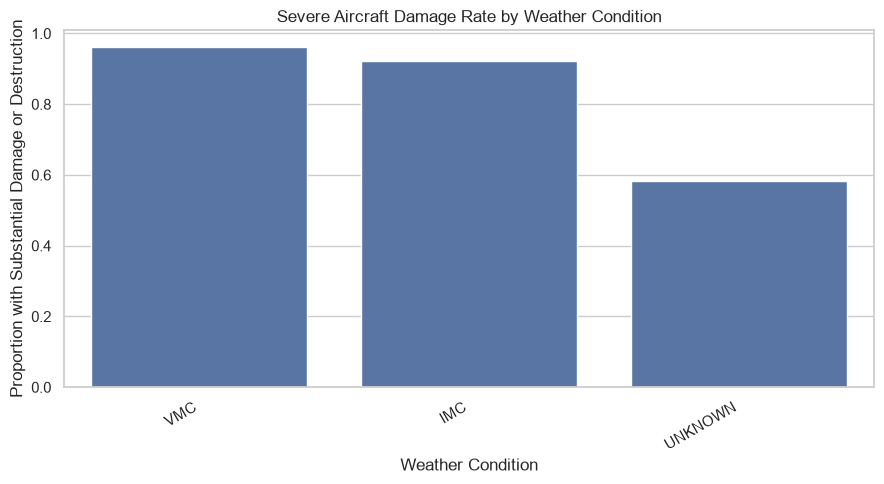

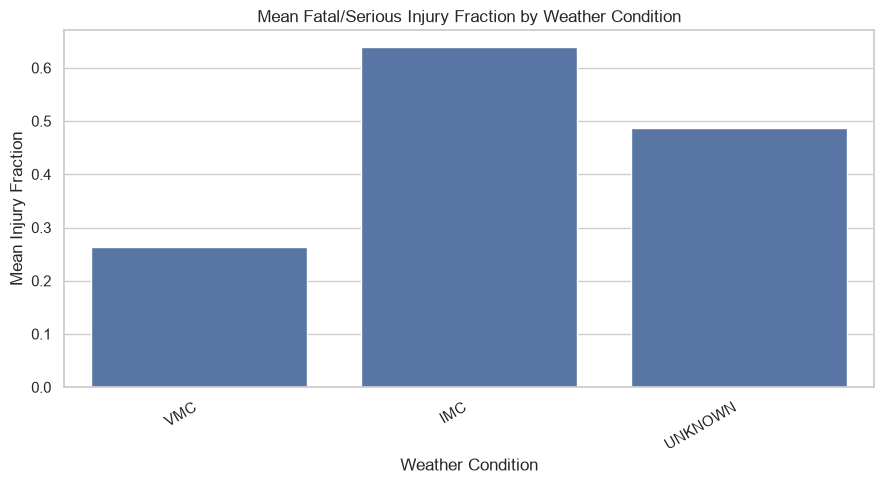

In [33]:
#weather
sns.set_theme(style="whitegrid")

df = aviation_df.copy()

# Clean weather labels and damage categories
df["Weather.Condition"] = (
    df["Weather.Condition"]
    .astype("string")
    .str.strip()
    .str.upper()
)

df["Aircraft.damage"] = (
    df["Aircraft.damage"]
    .astype("string")
    .str.strip()
    .str.title()
)

# Keep records with a known weather condition
weather_df = df.dropna(subset=["Weather.Condition"]).copy()
weather_df = weather_df[
    weather_df["Weather.Condition"] != ""
]

# Define severe damage: substantial damage or destroyed
weather_df["Severe_Damage"] = (
    weather_df["Aircraft.damage"]
    .str.lower()
    .isin(["substantial", "destroyed"])
)

# Summarize damage and injuries by weather condition
weather_summary = (
    weather_df.groupby("Weather.Condition")
    .agg(
        Accident_Count=("Event.Id", "count"),
        Severe_Damage_Rate=("Severe_Damage", "mean"),
        Mean_Fatal_Injuries=("Total.Fatal.Injuries", "mean"),
        Mean_Serious_Injuries=("Total.Serious.Injuries", "mean"),
        Mean_Injury_Fraction=(
            "Serious.Fatal.Injury.Fraction", "mean"
        )
    )
    .sort_values("Accident_Count", ascending=False)
)

display(weather_summary)

# Plot 1: Severe damage rate by weather condition
damage_plot = weather_summary.reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(
    data=damage_plot,
    x="Weather.Condition",
    y="Severe_Damage_Rate",
    errorbar=None
)
plt.title("Severe Aircraft Damage Rate by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Proportion with Substantial Damage or Destruction")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

# Plot 2: Mean serious/fatal injury fraction by weather
plt.figure(figsize=(9, 5))
sns.barplot(
    data=damage_plot,
    x="Weather.Condition",
    y="Mean_Injury_Fraction",
    errorbar=None
)
plt.title("Mean Fatal/Serious Injury Fraction by Weather Condition")
plt.xlabel("Weather Condition")
plt.ylabel("Mean Injury Fraction")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


,Accident_Count,Severe_Damage_Rate,Mean_Fatal_Injuries,Mean_Serious_Injuries,Mean_Injury_Fraction
Number.of.Engines,,,,,
1.0,13458,0.989315,0.316819,0.263079,0.292748
2.0,2560,0.864464,1.282962,0.578220,0.280168
3.0,28,0.619048,3.809524,0.772727,0.094549
4.0,76,0.444444,3.820896,1.121212,0.123809


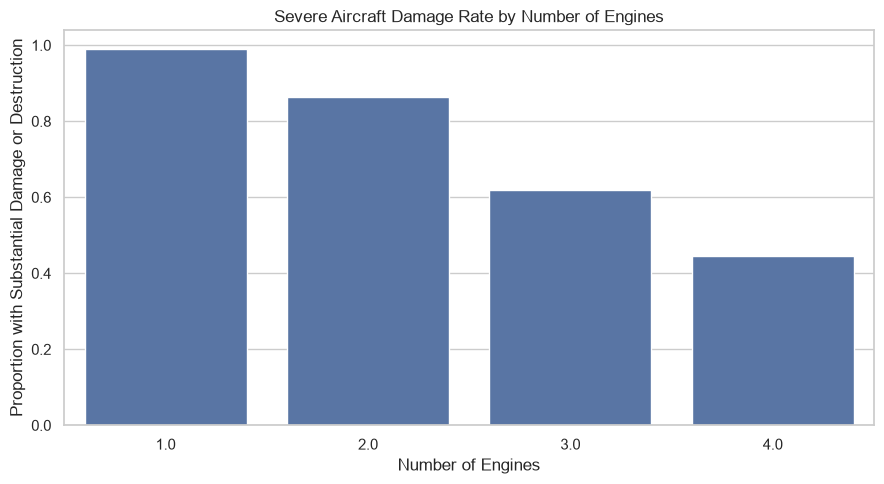

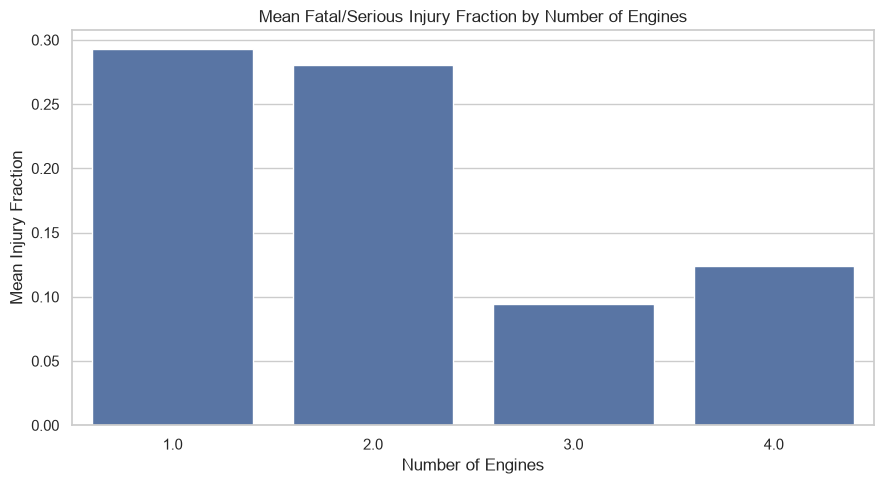

In [34]:

# Keep records with a known number of engines
engine_df = df.dropna(
    subset=["Number.of.Engines"]
).copy()

# Convert engine count to numeric
engine_df["Number.of.Engines"] = pd.to_numeric(
    engine_df["Number.of.Engines"],
    errors="coerce"
)

engine_df = engine_df.dropna(
    subset=["Number.of.Engines"]
)

# Remove invalid engine counts
engine_df = engine_df[
    engine_df["Number.of.Engines"] > 0
].copy()

# Define severe damage, leaving unknown damage as missing
engine_df["Severe_Damage"] = np.where(
    engine_df["Aircraft.damage"].isna(),
    np.nan,
    engine_df["Aircraft.damage"]
    .str.lower()
    .isin(["substantial", "destroyed"])
)

# Summarize damage and injury outcomes by engine count
engine_summary = (
    engine_df.groupby("Number.of.Engines")
    .agg(
        Accident_Count=("Event.Id", "count"),
        Severe_Damage_Rate=("Severe_Damage", "mean"),
        Mean_Fatal_Injuries=("Total.Fatal.Injuries", "mean"),
        Mean_Serious_Injuries=("Total.Serious.Injuries", "mean"),
        Mean_Injury_Fraction=(
            "Serious.Fatal.Injury.Fraction", "mean"
        )
    )
    .sort_index()
)

display(engine_summary)

# Plot 1: Severe damage rate by number of engines
engine_plot = engine_summary.reset_index()

plt.figure(figsize=(9, 5))
sns.barplot(
    data=engine_plot,
    x="Number.of.Engines",
    y="Severe_Damage_Rate",
    errorbar=None
)
plt.title("Severe Aircraft Damage Rate by Number of Engines")
plt.xlabel("Number of Engines")
plt.ylabel("Proportion with Substantial Damage or Destruction")
plt.tight_layout()
plt.show()

# Plot 2: Mean fatal/serious injury fraction by engine count
plt.figure(figsize=(9, 5))
sns.barplot(
    data=engine_plot,
    x="Number.of.Engines",
    y="Mean_Injury_Fraction",
    errorbar=None
)
plt.title("Mean Fatal/Serious Injury Fraction by Number of Engines")
plt.xlabel("Number of Engines")
plt.ylabel("Mean Injury Fraction")
plt.tight_layout()
plt.show()
